In [41]:
import numpy as np

**Module** is an abstract class which defines fundamental methods necessary for a training a neural network. You do not need to change anything here, just read the comments.

In [42]:
class Module(object):
    """
    Basically, you can think of a module as of a something (black box)
    which can process `input` data and produce `ouput` data.
    This is like applying a function which is called `forward`:

        output = module.forward(input)

    The module should be able to perform a backward pass: to differentiate the `forward` function.
    More, it should be able to differentiate it if is a part of chain (chain rule).
    The latter implies there is a gradient from previous step of a chain rule.

        gradInput = module.backward(input, gradOutput)
    """
    def __init__ (self):
        self.output = None
        self.gradInput = None
        self.training = True

    def forward(self, input):
        """
        Takes an input object, and computes the corresponding output of the module.
        """
        return self.updateOutput(input)

    def backward(self,input, gradOutput):
        """
        Performs a backpropagation step through the module, with respect to the given input.

        This includes
         - computing a gradient w.r.t. `input` (is needed for further backprop),
         - computing a gradient w.r.t. parameters (to update parameters while optimizing).
        """
        self.updateGradInput(input, gradOutput)
        self.accGradParameters(input, gradOutput)
        return self.gradInput


    def updateOutput(self, input):
        """
        Computes the output using the current parameter set of the class and input.
        This function returns the result which is stored in the `output` field.

        Make sure to both store the data in `output` field and return it.
        """

        # The easiest case:

        self.output = input
        return self.output

        pass

    def updateGradInput(self, input, gradOutput):
        """
        Computing the gradient of the module with respect to its own input.
        This is returned in `gradInput`. Also, the `gradInput` state variable is updated accordingly.

        The shape of `gradInput` is always the same as the shape of `input`.

        Make sure to both store the gradients in `gradInput` field and return it.
        """

        # The easiest case:

        self.gradInput = gradOutput
        return self.gradInput

        pass

    def accGradParameters(self, input, gradOutput):
        """
        Computing the gradient of the module with respect to its own parameters.
        No need to override if module has no parameters (e.g. ReLU).
        """
        pass

    def zeroGradParameters(self):
        """
        Zeroes `gradParams` variable if the module has params.
        """
        pass

    def getParameters(self):
        """
        Returns a list with its parameters.
        If the module does not have parameters return empty list.
        """
        return []

    def getGradParameters(self):
        """
        Returns a list with gradients with respect to its parameters.
        If the module does not have parameters return empty list.
        """
        return []

    def train(self):
        """
        Sets training mode for the module.
        Training and testing behaviour differs for Dropout, BatchNorm.
        """
        self.training = True

    def evaluate(self):
        """
        Sets evaluation mode for the module.
        Training and testing behaviour differs for Dropout, BatchNorm.
        """
        self.training = False

    def __repr__(self):
        """
        Pretty printing. Should be overrided in every module if you want
        to have readable description.
        """
        return "Module"

# Sequential container

**Define** a forward and backward pass procedures.

In [43]:
class Sequential(Module):
    """
         This class implements a container, which processes `input` data sequentially.

         `input` is processed by each module (layer) in self.modules consecutively.
         The resulting array is called `output`.
    """

    def __init__ (self):
        super(Sequential, self).__init__()
        self.modules = []

    def add(self, module):
        """
        Adds a module to the container.
        """
        self.modules.append(module)

    def updateOutput(self, input):
        """
        Basic workflow of FORWARD PASS:

            y_0    = module[0].forward(input)
            y_1    = module[1].forward(y_0)
            ...
            output = module[n-1].forward(y_{n-2})


        Just write a little loop.
        """

        # Your code goes here. ################################################
        self.intermediates = [input]
        self.output = input
        for module in self.modules:
            self.output = module.forward(self.output)
            self.intermediates.append(self.output)
        return self.output

    def backward(self, input, gradOutput):
        """
        Workflow of BACKWARD PASS:

            g_{n-1} = module[n-1].backward(y_{n-2}, gradOutput)
            g_{n-2} = module[n-2].backward(y_{n-3}, g_{n-1})
            ...
            g_1 = module[1].backward(y_0, g_2)
            gradInput = module[0].backward(input, g_1)


        !!!

        To ech module you need to provide the input, module saw while forward pass,
        it is used while computing gradients.
        Make sure that the input for `i-th` layer the output of `module[i]` (just the same input as in forward pass)
        and NOT `input` to this Sequential module.

        !!!

        """
        # Your code goes here. ################################################
        grad_input = gradOutput
        for i in range(len(self.modules) - 1, -1, -1):
            grad_input = self.modules[i].backward(self.intermediates[i], grad_input)
            
            self.gradInput = grad_input
        return self.gradInput


    def zeroGradParameters(self):
        for module in self.modules:
            module.zeroGradParameters()

    def getParameters(self):
        """
        Should gather all parameters in a list.
        """
        return [x.getParameters() for x in self.modules]

    def getGradParameters(self):
        """
        Should gather all gradients w.r.t parameters in a list.
        """
        return [x.getGradParameters() for x in self.modules]

    def __repr__(self):
        string = "".join([str(x) + '\n' for x in self.modules])
        return string

    def __getitem__(self,x):
        return self.modules.__getitem__(x)

    def train(self):
        """
        Propagates training parameter through all modules
        """
        self.training = True
        for module in self.modules:
            module.train()

    def evaluate(self):
        """
        Propagates training parameter through all modules
        """
        self.training = False
        for module in self.modules:
            module.evaluate()

# Layers

## 1 (0.2). Linear transform layer
Also known as dense layer, fully-connected layer, FC-layer, InnerProductLayer (in caffe), affine transform
- input:   **`batch_size x n_feats1`**
- output: **`batch_size x n_feats2`**

In [44]:
class Linear(Module):
    """
    A module which applies a linear transformation
    A common name is fully-connected layer, InnerProductLayer in caffe.

    The module should work with 2D input of shape (n_samples, n_feature).
    """
    def __init__(self, n_in, n_out):
        super(Linear, self).__init__()

        # This is a nice initialization
        stdv = 1./np.sqrt(n_in)
        self.W = np.random.uniform(-stdv, stdv, size = (n_out, n_in))
        self.b = np.random.uniform(-stdv, stdv, size = n_out)

        self.gradW = np.zeros_like(self.W)
        self.gradb = np.zeros_like(self.b)

    def updateOutput(self, input):
        # Your code goes here. ################################################
        self.output = np.dot(input, self.W.T) + self.b
        return self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        self.gradInput = np.dot(gradOutput, self.W)
        return self.gradInput

    def accGradParameters(self, input, gradOutput):
        # Your code goes here. ################################################
        self.gradW += np.dot(gradOutput.T, input) 
        self.gradb += np.sum(gradOutput, axis=0)

    def zeroGradParameters(self):
        self.gradW.fill(0)
        self.gradb.fill(0)

    def getParameters(self):
        return [self.W, self.b]

    def getGradParameters(self):
        return [self.gradW, self.gradb]

    def __repr__(self):
        s = self.W.shape
        q = 'Linear %d -> %d' %(s[1],s[0])
        return q

## 2. (0.2) SoftMax
- input:   **`batch_size x n_feats`**
- output: **`batch_size x n_feats`**

$\text{softmax}(x)_i = \frac{\exp x_i} {\sum_j \exp x_j}$

Recall that $\text{softmax}(x) == \text{softmax}(x - \text{const})$. It makes possible to avoid computing exp() from large argument.

In [45]:
class SoftMax(Module):
    def __init__(self):
         super(SoftMax, self).__init__()

    def updateOutput(self, input):
        # start with normalization for numerical stability
        self.output = np.subtract(input, input.max(axis=1, keepdims=True))

        # Your code goes here. ################################################
        exp_values = np.exp(self.output)
        self.output = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        return self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        softmax = self.output
        sum_grad_softmax = np.sum(gradOutput * softmax, axis=1, keepdims=True)
        
        self.gradInput = softmax * (gradOutput - sum_grad_softmax)
        return self.gradInput

    def __repr__(self):
        return "SoftMax"

## 3. (0.2) LogSoftMax
- input:   **`batch_size x n_feats`**
- output: **`batch_size x n_feats`**

$\text{logsoftmax}(x)_i = \log\text{softmax}(x)_i = x_i - \log {\sum_j \exp x_j}$

The main goal of this layer is to be used in computation of log-likelihood loss.

In [46]:
class LogSoftMax(Module):
    def __init__(self):
         super(LogSoftMax, self).__init__()

    def updateOutput(self, input):
        # start with normalization for numerical stability
        self.output = np.subtract(input, input.max(axis=1, keepdims=True))

        # Your code goes here. ################################################
        log_sum_exp = np.log(np.sum(np.exp(self.output), axis=1, keepdims=True))
        self.output = self.output - log_sum_exp
        return self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        softmax = np.exp(self.output)
        sum_grad = np.sum(gradOutput, axis=1, keepdims=True)
        self.gradInput = gradOutput - softmax * sum_grad
        return self.gradInput

    def __repr__(self):
        return "LogSoftMax"

## 4. (0.3) Batch normalization
One of the most significant recent ideas that impacted NNs a lot is [**Batch normalization**](http://arxiv.org/abs/1502.03167). The idea is simple, yet effective: the features should be whitened ($mean = 0$, $std = 1$) all the way through NN. This improves the convergence for deep models letting it train them for days but not weeks. **You are** to implement the first part of the layer: features normalization. The second part (`ChannelwiseScaling` layer) is implemented below.

- input:   **`batch_size x n_feats`**
- output: **`batch_size x n_feats`**

The layer should work as follows. While training (`self.training == True`) it transforms input as $$y = \frac{x - \mu}  {\sqrt{\sigma + \epsilon}}$$
where $\mu$ and $\sigma$ - mean and variance of feature values in **batch** and $\epsilon$ is just a small number for numericall stability. Also during training, layer should maintain exponential moving average values for mean and variance:
```
    self.moving_mean = self.moving_mean * alpha + batch_mean * (1 - alpha)
    self.moving_variance = self.moving_variance * alpha + batch_variance * (1 - alpha)
```
During testing (`self.training == False`) the layer normalizes input using moving_mean and moving_variance.

Note that decomposition of batch normalization on normalization itself and channelwise scaling here is just a common **implementation** choice. In general "batch normalization" always assumes normalization + scaling.

In [47]:
class BatchNormalization(Module):
    EPS = 1e-3
    def __init__(self, alpha = 0.):
        super(BatchNormalization, self).__init__()
        self.alpha = alpha
        self.moving_mean = None
        self.moving_variance = None

    def updateOutput(self, input):
        # Your code goes here. ################################################
        # use self.EPS please
        if self.training:
            self.batch_mean = np.mean(input, axis=0, keepdims=True)
            self.batch_variance = np.var(input, axis=0, keepdims=True)
            
            self.normalized = (input - self.batch_mean) / np.sqrt(self.batch_variance + self.EPS)
            
            if self.moving_mean is None:
                self.moving_mean = self.batch_mean.copy()
                self.moving_variance = self.batch_variance.copy()
            else:
                self.moving_mean = self.moving_mean * self.alpha + self.batch_mean * (1 - self.alpha)
                self.moving_variance = self.moving_variance * self.alpha + self.batch_variance * (1 - self.alpha)
            
            self.output = self.normalized
        else:
            if self.moving_mean is not None and self.moving_variance is not None:
                self.output = (input - self.moving_mean) / np.sqrt(self.moving_variance + self.EPS)
            else:
                self.output = input

        return self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        if self.training:
            N = input.shape[0]
            var = self.batch_variance + self.EPS
            sqrt_var = np.sqrt(var)
            
            grad_x_hat = gradOutput
            
            grad_var = np.sum(grad_x_hat * (input - self.batch_mean) * (-0.5) * (var ** (-1.5)), axis=0, keepdims=True)
            grad_mean = np.sum(grad_x_hat * (-1 / sqrt_var), axis=0, keepdims=True)
            
            self.gradInput = grad_x_hat / sqrt_var
            self.gradInput += (2.0 / N) * grad_var * (input - self.batch_mean)
            self.gradInput += grad_mean / N
        else:
            if self.moving_mean is not None and self.moving_variance is not None:
                sqrt_var = np.sqrt(self.moving_variance + self.EPS)
                self.gradInput = gradOutput / sqrt_var
            else:
                self.gradInput = gradOutput
        
        return self.gradInput

    def __repr__(self):
        return "BatchNormalization"

In [48]:
class ChannelwiseScaling(Module):
    """
       Implements linear transform of input y = \gamma * x + \beta
       where \gamma, \beta - learnable vectors of length x.shape[-1]
    """
    def __init__(self, n_out):
        super(ChannelwiseScaling, self).__init__()

        stdv = 1./np.sqrt(n_out)
        self.gamma = np.random.uniform(-stdv, stdv, size=n_out)
        self.beta = np.random.uniform(-stdv, stdv, size=n_out)

        self.gradGamma = np.zeros_like(self.gamma)
        self.gradBeta = np.zeros_like(self.beta)

    def updateOutput(self, input):
        self.output = input * self.gamma + self.beta
        return self.output

    def updateGradInput(self, input, gradOutput):
        self.gradInput = gradOutput * self.gamma
        return self.gradInput

    def accGradParameters(self, input, gradOutput):
        self.gradBeta = np.sum(gradOutput, axis=0)
        self.gradGamma = np.sum(gradOutput*input, axis=0)

    def zeroGradParameters(self):
        self.gradGamma.fill(0)
        self.gradBeta.fill(0)

    def getParameters(self):
        return [self.gamma, self.beta]

    def getGradParameters(self):
        return [self.gradGamma, self.gradBeta]

    def __repr__(self):
        return "ChannelwiseScaling"

<>:2: SyntaxWarning: invalid escape sequence '\g'
<>:2: SyntaxWarning: invalid escape sequence '\g'
/var/folders/wz/7gxs93rj2710v6r1rv_dzzdw0000gn/T/ipykernel_89302/3092293347.py:2: SyntaxWarning: invalid escape sequence '\g'
  """


Practical notes. If BatchNormalization is placed after a linear transformation layer (including dense layer, convolutions, channelwise scaling) that implements function like `y = weight * x + bias`, than bias adding become useless and could be omitted since its effect will be discarded while batch mean subtraction. If BatchNormalization (followed by `ChannelwiseScaling`) is placed before a layer that propagates scale (including ReLU, LeakyReLU) followed by any linear transformation layer than parameter `gamma` in `ChannelwiseScaling` could be freezed since it could be absorbed into the linear transformation layer.

## 5. (0.3) Dropout
Implement [**dropout**](https://www.cs.toronto.edu/~hinton/absps/JMLRdropout.pdf). The idea and implementation is really simple: just multimply the input by $Bernoulli(p)$ mask. Here $p$ is probability of an element to be zeroed.

This has proven to be an effective technique for regularization and preventing the co-adaptation of neurons.

While training (`self.training == True`) it should sample a mask on each iteration (for every batch), zero out elements and multiply elements by $1 / (1 - p)$. The latter is needed for keeping mean values of features close to mean values which will be in test mode. When testing this module should implement identity transform i.e. `self.output = input`.

- input:   **`batch_size x n_feats`**
- output: **`batch_size x n_feats`**

In [49]:
class Dropout(Module):
    def __init__(self, p=0.5):
        super(Dropout, self).__init__()

        self.p = p
        self.mask = None

    def updateOutput(self, input):
        # Your code goes here. ################################################
        if self.training:
            # Создаем маску: 1 с вероятностью (1-p), 0 с вероятностью p
            self.mask = np.random.binomial(1, 1 - self.p, size=input.shape)
            # Применяем маску и масштабируем
            self.output = input * self.mask / (1 - self.p)
        else:
            self.output = input
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        if self.training:
            self.gradInput = gradOutput * self.mask / (1 - self.p)
        else:
            self.gradInput = gradOutput
        return self.gradInput

    def __repr__(self):
        return "Dropout"

#6. (2.0) Conv2d
Implement [**Conv2d**](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html). Use only this list of parameters: (in_channels, out_channels, kernel_size, stride, padding, bias, padding_mode) and fix dilation=1 and groups=1.

In [50]:
class Conv2d(Module):
    def __init__(self, in_channels, out_channels, kernel_size,
                 stride=1, padding=0, bias=True, padding_mode='zeros'):
        super(Conv2d, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        self.bias = bias
        self.padding_mode = padding_mode

    def updateOutput(self, input):
        # Your code goes here. ################################################
        batch_size, _, h_in, w_in = input.shape
        if self.padding != 0:
            if self.padding_mode == 'zeros':
                padded = np.pad(input, 
                                ((0, 0), (0, 0),
                                 (self.padding, self.padding),
                                 (self.padding, self.padding)),
                                 mode='constant')
            else:
                pad_width = ((0, 0), (0, 0), 
                            (self.padding, self.padding), 
                            (self.padding, self.padding))
                padded = np.pad(input, pad_width, mode=self.padding_mode)
        else:
            padded = input
        
        #размеры выхода
        h_out = (h_in + 2*self.padding - self.kernel_size) // self.stride + 1
        w_out = (w_in + 2*self.padding - self.kernel_size) // self.stride + 1
    
        self.output = np.zeros((batch_size, self.out_channels, h_out, w_out))
        
        for n in range(batch_size):
            for c_out in range(self.out_channels):
                for h in range(h_out):
                    h_start = h * self.stride
                    for w in range(w_out):
                        w_start = w * self.stride
                        region = padded[n, :, h_start:h_start+self.kernel_size, w_start:w_start+self.kernel_size]
                        self.output[n, c_out, h, w] = np.sum(region * self.weight[c_out]) + (self.bias[c_out] if self.bias is not None else 0)

        return self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        batch_size, _, h_in, w_in = input.shape
        
        if self.padding != 0:
            if self.padding_mode == 'zeros':
                padded = np.pad(input, 
                                ((0, 0), (0, 0),
                                 (self.padding, self.padding),
                                 (self.padding, self.padding)),
                                 mode='constant')
            else:
                pad_width = ((0, 0), (0, 0), 
                            (self.padding, self.padding), 
                            (self.padding, self.padding))
                padded = np.pad(input, pad_width, mode=self.padding_mode)
        else:
            padded = input
        
        h_padded = h_in + 2*self.padding
        w_padded = w_in + 2*self.padding
        
        self.gradInput = np.zeros_like(padded)
        
        for n in range(batch_size):
            for c_in in range(self.in_channels):
                for h in range(h_padded):
                    for w in range(w_padded):
                        grad_val = 0
                        for c_out in range(self.out_channels):
                            for kh in range(self.kernel_size):
                                for kw in range(self.kernel_size):
                                    h_out_start = h - kh
                                    w_out_start = w - kw
                                    
                                    if h_out_start % self.stride == 0 and w_out_start % self.stride == 0:
                                        h_out = h_out_start // self.stride
                                        w_out = w_out_start // self.stride
                                        
                                        if 0 <= h_out < gradOutput.shape[2] and 0 <= w_out < gradOutput.shape[3]:
                                            grad_val += gradOutput[n, c_out, h_out, w_out] * self.weight[c_out, c_in, kh, kw]
                        
                        self.gradInput[n, c_in, h, w] = grad_val
        
        if self.padding != 0:
            self.gradInput = self.gradInput[:, :, self.padding:-self.padding, self.padding:-self.padding]
        
        return self.gradInput

    def __repr__(self):
        return "Conv2d"

#7. (0.5) Implement [**MaxPool2d**](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) and [**AvgPool2d**](https://pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html). Use only parameters like kernel_size, stride, padding (negative infinity for maxpool and zero for avgpool) and other parameters fixed as in framework.

In [51]:
class MaxPool2d(Module):
    def __init__(self, kernel_size, stride, padding):
        super(MaxPool2d, self).__init__()

        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

    def updateOutput(self, input):
        # Your code goes here. ################################################
        batch_size, n_channels, h_in, w_in = input.shape
        if self.padding != 0:
            padded = np.pad(input, 
                           ((0, 0), (0, 0),
                            (self.padding, self.padding),
                            (self.padding, self.padding)),
                           mode='constant', constant_values=-np.inf)
        else:
            padded = input

        h_out = (h_in + 2*self.padding - self.kernel_size) // self.stride + 1
        w_out = (w_in + 2*self.padding - self.kernel_size) // self.stride + 1

        self.output = np.zeros((batch_size, n_channels, h_out, w_out))
        self.max_indices = np.zeros((batch_size, n_channels, h_out, w_out, 2), dtype=int)
        
        # Max pooling
        for n in range(batch_size):
            for c in range(n_channels):
                for h in range(h_out):
                    h_start = h * self.stride
                    for w in range(w_out):
                        w_start = w * self.stride
                        window = padded[n, c, h_start:h_start+self.kernel_size, w_start:w_start+self.kernel_size]
                        max_val = np.max(window)
                        self.output[n, c, h, w] = max_val
                        
                        idx = np.argmax(window)
                        idx_h = idx // self.kernel_size
                        idx_w = idx % self.kernel_size
                        self.max_indices[n, c, h, w] = [h_start + idx_h, w_start + idx_w]

        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        batch_size, n_channels, h_in, w_in = input.shape
        if self.padding != 0:
            padded = np.pad(input, 
                           ((0, 0), (0, 0),
                            (self.padding, self.padding),
                            (self.padding, self.padding)),
                           mode='constant', constant_values=-np.inf)
        else:
            padded = input
        
        h_padded = h_in + 2*self.padding
        w_padded = w_in + 2*self.padding
        self.gradInput = np.zeros_like(padded)
        for n in range(batch_size):
            for c in range(n_channels):
                for h in range(gradOutput.shape[2]):
                    for w in range(gradOutput.shape[3]):
                        idx_h, idx_w = self.max_indices[n, c, h, w]
                        self.gradInput[n, c, idx_h, idx_w] += gradOutput[n, c, h, w]
        if self.padding != 0:
            self.gradInput = self.gradInput[:, :, self.padding:-self.padding, self.padding:-self.padding]
 
        return self.gradInput

    def __repr__(self):
        return "MaxPool2d"

class AvgPool2d(Module):
    def __init__(self, kernel_size, stride, padding):
        super(AvgPool2d, self).__init__()

        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

    def updateOutput(self, input):
        # Your code goes here. ################################################
        batch_size, n_channels, h_in, w_in = input.shape
        if self.padding != 0:
            padded = np.pad(input, 
                           ((0, 0), (0, 0),
                            (self.padding, self.padding),
                            (self.padding, self.padding)),
                           mode='constant', constant_values=0)
        else:
            padded = input
        h_out = (h_in + 2*self.padding - self.kernel_size) // self.stride + 1
        w_out = (w_in + 2*self.padding - self.kernel_size) // self.stride + 1
        self.output = np.zeros((batch_size, n_channels, h_out, w_out))
        
        pool_size = self.kernel_size * self.kernel_size
        
        for n in range(batch_size):
            for c in range(n_channels):
                for h in range(h_out):
                    h_start = h * self.stride
                    for w in range(w_out):
                        w_start = w * self.stride
                        window = padded[n, c, h_start:h_start+self.kernel_size, w_start:w_start+self.kernel_size]
                        self.output[n, c, h, w] = np.mean(window)
        
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        batch_size, n_channels, h_in, w_in = input.shape
        if self.padding != 0:
            padded = np.pad(input, 
                           ((0, 0), (0, 0),
                            (self.padding, self.padding),
                            (self.padding, self.padding)),
                           mode='constant', constant_values=0)
        else:
            padded = input
        
        h_padded = h_in + 2*self.padding
        w_padded = w_in + 2*self.padding
        
        self.gradInput = np.zeros_like(padded)
        
        pool_size = self.kernel_size * self.kernel_size

        for n in range(batch_size):
            for c in range(n_channels):
                for h in range(gradOutput.shape[2]):
                    h_start = h * self.stride
                    for w in range(gradOutput.shape[3]):
                        w_start = w * self.stride
                       
                        grad_val = gradOutput[n, c, h, w] / pool_size
                        self.gradInput[n, c, h_start:h_start+self.kernel_size, w_start:w_start+self.kernel_size] += grad_val
        
        if self.padding != 0:
            self.gradInput = self.gradInput[:, :, self.padding:-self.padding, self.padding:-self.padding]
        return self.gradInput

    def __repr__(self):
        return "AvgPool2d"

#8. (0.3) Implement **GlobalMaxPool2d** and **GlobalAvgPool2d**. They do not have testing and parameters are up to you but they must aggregate information within channels. Write test functions for these layers on your own.

In [ ]:
import numpy as np

class GlobalMaxPool2d(Module):
    def __init__(self):
        super(GlobalMaxPool2d, self).__init__()

    def updateOutput(self, input):
        self.output = np.max(input, axis=(2, 3), keepdims=True)
        self.max_indices = np.argmax(input.reshape(input.shape[0], input.shape[1], -1), axis=2)
        return self.output

    def updateGradInput(self, input, gradOutput):
        batch_size, n_channels, height, width = input.shape
        self.gradInput = np.zeros_like(input)
        for n in range(batch_size):
            for c in range(n_channels):
                idx = self.max_indices[n, c]
                self.gradInput[n, c, idx // width, idx % width] = gradOutput[n, c, 0, 0]
        return self.gradInput

    def __repr__(self):
        return "GlobalMaxPool2d"


class GlobalAvgPool2d(Module):
    def __init__(self):
        super(GlobalAvgPool2d, self).__init__()

    def updateOutput(self, input):
        self.output = np.mean(input, axis=(2, 3), keepdims=True)
        return self.output

    def updateGradInput(self, input, gradOutput):
        pool_size = input.shape[2] * input.shape[3]
        self.gradInput = np.broadcast_to(gradOutput / pool_size, input.shape)
        return self.gradInput

    def __repr__(self):
        return "GlobalAvgPool2d"
    



Max Output: [[[[4.]]]]


IndexError: too many indices for array: array is 2-dimensional, but 4 were indexed

#9. (0.2) Implement [**Flatten**](https://pytorch.org/docs/stable/generated/torch.flatten.html)

In [53]:
class Flatten(Module):
    def __init__(self, start_dim=0, end_dim=-1):
        super(Flatten, self).__init__()

        self.start_dim = start_dim
        self.end_dim = end_dim

    def updateOutput(self, input):
        # Your code goes here. ################################################
        shape = input.shape
        start = self.start_dim if self.start_dim >= 0 else len(shape) + self.start_dim
        end = self.end_dim if self.end_dim >= 0 else len(shape) + self.end_dim
        
        # Размеры до start_dim, flattened размер, размеры после end_dim
        new_shape = shape[:start] + (-1,) + shape[end+1:]
        self.output = input.reshape(new_shape)
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        self.gradInput = gradOutput.reshape(input.shape)
        return self.gradInput

    def __repr__(self):
        return "Flatten"

# Activation functions

Here's the complete example for the **Rectified Linear Unit** non-linearity (aka **ReLU**):

In [54]:
class ReLU(Module):
    def __init__(self):
         super(ReLU, self).__init__()

    def updateOutput(self, input):
        self.output = np.maximum(input, 0)
        return self.output

    def updateGradInput(self, input, gradOutput):
        self.gradInput = np.multiply(gradOutput , input > 0)
        return self.gradInput

    def __repr__(self):
        return "ReLU"

## 10. (0.1) Leaky ReLU
Implement [**Leaky Rectified Linear Unit**](http://en.wikipedia.org/wiki%2FRectifier_%28neural_networks%29%23Leaky_ReLUs). Expriment with slope.

In [55]:
class LeakyReLU(Module):
    def __init__(self, slope = 0.03):
        super(LeakyReLU, self).__init__()

        self.slope = slope

    def updateOutput(self, input):
        # Your code goes here. ################################################
        self.output = np.where(input > 0, input, self.slope * input)
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        self.gradInput = np.where(input > 0, gradOutput, self.slope * gradOutput)
        return self.gradInput

    def __repr__(self):
        return "LeakyReLU"

## 11. (0.1) ELU
Implement [**Exponential Linear Units**](http://arxiv.org/abs/1511.07289) activations.

In [56]:
class ELU(Module):
    def __init__(self, alpha = 1.0):
        super(ELU, self).__init__()

        self.alpha = alpha

    def updateOutput(self, input):
        # Your code goes here. ################################################
        self.output = np.where(input > 0, input, self.alpha * (np.exp(input) - 1))
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        grad = np.where(input > 0, 1, self.alpha * np.exp(input))
        self.gradInput = gradOutput * grad
        return self.gradInput

    def __repr__(self):
        return "ELU"

## 12. (0.1) SoftPlus
Implement [**SoftPlus**](https://en.wikipedia.org/wiki%2FRectifier_%28neural_networks%29) activations. Look, how they look a lot like ReLU.

In [57]:
class SoftPlus(Module):
    def __init__(self):
        super(SoftPlus, self).__init__()

    def updateOutput(self, input):
        # Your code goes here. ################################################
        self.output = np.log(1 + np.exp(input))
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
         self.gradInput = gradOutput * (1 / (1 + np.exp(-input)))
         return self.gradInput

    def __repr__(self):
        return "SoftPlus"

#13. (0.2) Gelu
Implement [**Gelu**](https://pytorch.org/docs/stable/generated/torch.nn.GELU.html) activations.

In [58]:
class Gelu(Module):
    def __init__(self):
        super(SoftPlus, self).__init__()

    def updateOutput(self, input):
        # Your code goes here. ################################################
        x = input
        coeff = np.sqrt(2 / np.pi)
        self.output = 0.5 * x * (1 + np.tanh(coeff * (x + 0.044715 * x**3)))
        return  self.output

    def updateGradInput(self, input, gradOutput):
        # Your code goes here. ################################################
        x = input
        coeff = np.sqrt(2 / np.pi)
        tanh_arg = coeff * (x + 0.044715 * x**3)
        tanh_val = np.tanh(tanh_arg)
 
        tanh_deriv = 1 - tanh_val**2

        arg_deriv = coeff * (1 + 3 * 0.044715 * x**2)
  
        grad_act = 0.5 * (1 + tanh_val) + 0.5 * x * tanh_deriv * arg_deriv
        self.gradInput = gradOutput * grad_act
        return self.gradInput

    def __repr__(self):
        return "Gelu"

# Criterions

Criterions are used to score the models answers.

In [59]:
class Criterion(object):
    def __init__ (self):
        self.output = None
        self.gradInput = None

    def forward(self, input, target):
        """
            Given an input and a target, compute the loss function
            associated to the criterion and return the result.

            For consistency this function should not be overrided,
            all the code goes in `updateOutput`.
        """
        return self.updateOutput(input, target)

    def backward(self, input, target):
        """
            Given an input and a target, compute the gradients of the loss function
            associated to the criterion and return the result.

            For consistency this function should not be overrided,
            all the code goes in `updateGradInput`.
        """
        return self.updateGradInput(input, target)

    def updateOutput(self, input, target):
        """
        Function to override.
        """
        return self.output

    def updateGradInput(self, input, target):
        """
        Function to override.
        """
        return self.gradInput

    def __repr__(self):
        """
        Pretty printing. Should be overrided in every module if you want
        to have readable description.
        """
        return "Criterion"

The **MSECriterion**, which is basic L2 norm usually used for regression, is implemented here for you.
- input:   **`batch_size x n_feats`**
- target: **`batch_size x n_feats`**
- output: **scalar**

In [60]:
class MSECriterion(Criterion):
    def __init__(self):
        super(MSECriterion, self).__init__()

    def updateOutput(self, input, target):
        self.output = np.sum(np.power(input - target,2)) / input.shape[0]
        return self.output

    def updateGradInput(self, input, target):
        self.gradInput  = (input - target) * 2 / input.shape[0]
        return self.gradInput

    def __repr__(self):
        return "MSECriterion"

## 14. (0.2) Negative LogLikelihood criterion (numerically unstable)
You task is to implement the **ClassNLLCriterion**. It should implement [multiclass log loss](http://scikit-learn.org/stable/modules/model_evaluation.html#log-loss). Nevertheless there is a sum over `y` (target) in that formula,
remember that targets are one-hot encoded. This fact simplifies the computations a lot. Note, that criterions are the only places, where you divide by batch size. Also there is a small hack with adding small number to probabilities to avoid computing log(0).
- input:   **`batch_size x n_feats`** - probabilities
- target: **`batch_size x n_feats`** - one-hot representation of ground truth
- output: **scalar**



In [61]:
class ClassNLLCriterionUnstable(Criterion):
    EPS = 1e-15
    def __init__(self):
        a = super(ClassNLLCriterionUnstable, self)
        super(ClassNLLCriterionUnstable, self).__init__()

    def updateOutput(self, input, target):

        # Use this trick to avoid numerical errors
        input_clamp = np.clip(input, self.EPS, 1 - self.EPS)

        # Your code goes here. ################################################
        batch_size = input.shape[0]
        self.output = -np.sum(target * np.log(input_clamp)) / batch_size
        return self.output

    def updateGradInput(self, input, target):

        # Use this trick to avoid numerical errors
        input_clamp = np.clip(input, self.EPS, 1 - self.EPS)

        # Your code goes here. ################################################
        batch_size = input.shape[0]
        self.gradInput = -target / input_clamp / batch_size
        return self.gradInput

    def __repr__(self):
        return "ClassNLLCriterionUnstable"

## 15. (0.3) Negative LogLikelihood criterion (numerically stable)
- input:   **`batch_size x n_feats`** - log probabilities
- target: **`batch_size x n_feats`** - one-hot representation of ground truth
- output: **scalar**

Task is similar to the previous one, but now the criterion input is the output of log-softmax layer. This decomposition allows us to avoid problems with computation of forward and backward of log().

In [62]:
class ClassNLLCriterion(Criterion):
    def __init__(self):
        a = super(ClassNLLCriterion, self)
        super(ClassNLLCriterion, self).__init__()

    def updateOutput(self, input, target):
        # Your code goes here. ################################################
        batch_size = input.shape[0]
        self.output = -np.sum(target * input) / batch_size
        return self.output

    def updateGradInput(self, input, target):
        # Your code goes here. ################################################
        batch_size = input.shape[0]
        self.gradInput = -target / batch_size
        return self.gradInput

    def __repr__(self):
        return "ClassNLLCriterion"

1-я часть задания: реализация слоев, лосей и функций активации - 5 баллов. \\
2-я часть задания: реализация моделей на своих классах. Что должно быть:
  1. Выберите оптимизатор и реализуйте его, чтоб он работал с вами классами. - 1 балл.
  2. Модель для задачи мультирегрессии на выбраных вами данных. Использовать FCNN, dropout, batchnorm, MSE. Пробуйте различные фукнции активации. Для первой модели попробуйте большую, среднюю и маленькую модель. - 1 балл.
  3. Модель для задачи мультиклассификации на MNIST. Использовать свёртки, макспулы, флэттэны, софтмаксы - 1 балла.
  4. Автоэнкодер для выбранных вами данных. Должен быть на свёртках и полносвязных слоях, дропаутах, батчнормах и тд. - 2 балла. \\

Дополнительно в оценке каждой модели будет учитываться:
1. Наличие правильно выбранной метрики и лосс функции.
2. Отрисовка графиков лосей и метрик на трейне-валидации. Проверка качества модели на тесте.
3. Наличие шедулера для lr.
4. Наличие вормапа.
5. Наличие механизма ранней остановки и сохранение лучшей модели.
6. Свитч лося (метрики) и оптимайзера.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# пункт 1
class CustomSGD:
    def __init__(self, params, lr=0.01, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocities = [torch.zeros_like(p) for p in self.params]

    def step(self):
        with torch.no_grad():
            for p, v in zip(self.params, self.velocities):
                v.copy_(self.momentum * v + p.grad)
                p -= self.lr * v

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

# пункт 2
X_reg = torch.randn(1000, 10)
y_reg = X_reg @ torch.randn(10, 3) + 0.5

class MultiRegressionModel(nn.Module):
    def __init__(self, size='medium'):
        super().__init__()
        sizes = {'small': [16], 'medium': [64, 32], 'large': [256, 128, 64]}
        layers = []
        in_dim = 10
        for h in sizes[size]:
            layers.extend([
                nn.Linear(in_dim, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(0.2)
            ])
            in_dim = h
        layers.append(nn.Linear(in_dim, 3))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# пцнкт 3
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mnist_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)

class MNISTConvModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# пункт 4
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), 
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Flatten(),
            nn.Linear(16 * 14 * 14, 64)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(64, 16 * 14 * 14),
            nn.ReLU(),
            nn.Unflatten(1, (16, 14, 14)),
            nn.ConvTranspose2d(16, 1, 4, stride=2, padding=1), 
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

model_reg = MultiRegressionModel(size='large')
model_cls = MNISTConvModel()
model_ae = ConvAutoencoder()

optimizer_reg = CustomSGD(model_reg.parameters(), lr=0.001)
criterion_mse = nn.MSELoss()
criterion_cls = nn.NLLLoss()


100%|██████████| 9.91M/9.91M [00:07<00:00, 1.36MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 118kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.30MB/s]


--- Training MNIST Classification ---
Epoch 1: Val Loss: 0.1233 | Acc: 0.9622


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/optim/lr_scheduler.py:1060: UserWarning: To get the last learning rate computed by the scheduler, please use `get_last_lr()`.
  _warn_get_lr_called_within_step(self)


Epoch 2: Val Loss: 0.0739 | Acc: 0.9770
Epoch 3: Val Loss: 0.0556 | Acc: 0.9818
Epoch 4: Val Loss: 0.0495 | Acc: 0.9847
Epoch 5: Val Loss: 0.0403 | Acc: 0.9876


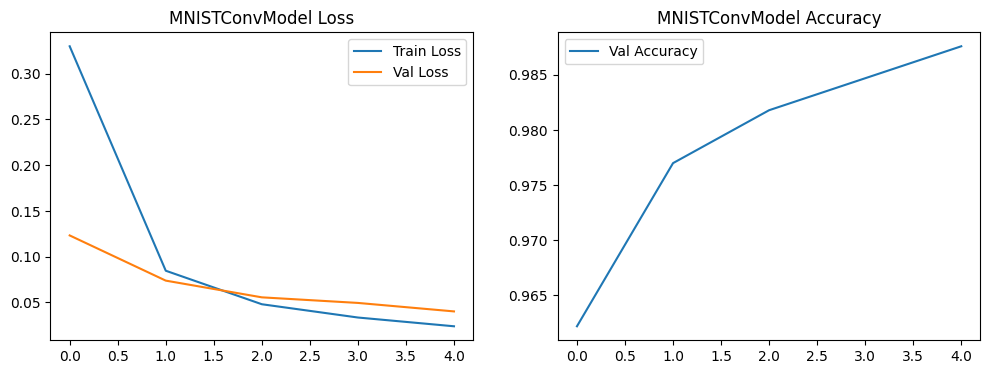

Final Test Loss for MNISTConvModel: 0.0292

--- Training Autoencoder ---
Epoch 1: Val Loss: 0.6990


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/optim/lr_scheduler.py:656: UserWarning: To get the last learning rate computed by the scheduler, please use `get_last_lr()`.
  _warn_get_lr_called_within_step(self)


Epoch 2: Val Loss: 0.5788
Epoch 3: Val Loss: 0.5433
Epoch 4: Val Loss: 0.5256
Epoch 5: Val Loss: 0.5151


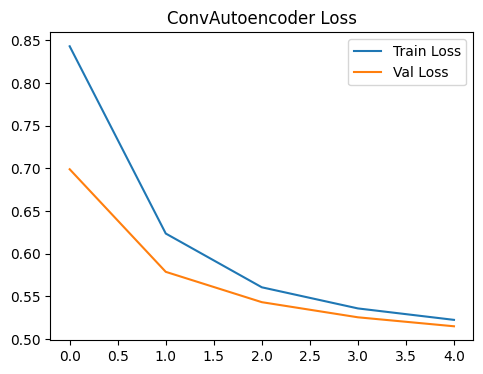

Final Test Loss for ConvAutoencoder: 0.5205


In [ ]:
import torch.optim.lr_scheduler as lr_scheduler
from torch.optim import Optimizer
import os


class CustomSGD(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        defaults = dict(lr=lr, momentum=momentum)
        super(CustomSGD, self).__init__(params, defaults)

    def step(self, closure=None):
        loss = None
        if closure is not None:
            loss = closure()

        for group in self.param_groups:
            momentum = group['momentum']
            lr = group['lr']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if 'velocity' not in state:
                    state['velocity'] = torch.zeros_like(p.data)
                
                v = state['velocity']
                v.copy_(momentum * v + p.grad.data)
                p.data.add_(v, alpha=-lr)
        return loss


class WarmupStepLR(lr_scheduler._LRScheduler):
    def __init__(self, optimizer, warmup_iters, main_scheduler, last_epoch=-1):
        self.warmup_iters = warmup_iters
        self.main_scheduler = main_scheduler
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        if self.last_epoch < self.warmup_iters:
            return [base_lr * (self.last_epoch + 1) / self.warmup_iters for base_lr in self.base_lrs]
        return self.main_scheduler.get_lr()

    def step(self, epoch=None):
        if self.last_epoch >= self.warmup_iters:
            self.main_scheduler.step(epoch)
        super().step(epoch)


class EarlyStopping:
    def __init__(self, patience=3, path='best_model.pt'):
        self.patience = patience
        self.counter = 0
        self.best_loss = float('inf')
        self.path = path

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            torch.save(model.state_dict(), self.path)
            self.counter = 0
            return False
        else:
            self.counter += 1
            return self.counter >= self.patience

def train_and_evaluate(model, train_loader, val_loader, test_loader, criterion, optimizer, scheduler, epochs=5, is_ae=False):
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    model_name = model.__class__.__name__
    save_path = f'best_{model_name}.pt'
    stopper = EarlyStopping(patience=3, path=save_path)

    for epoch in range(epochs):
        model.train()
        train_total_loss = 0
        for x, y in train_loader:
            target = x if is_ae else y
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, target)
            loss.backward()
            optimizer.step()
            train_total_loss += loss.item()
        
        scheduler.step()
        
        model.eval()
        val_total_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                target = x if is_ae else y
                out = model(x)
                val_total_loss += criterion(out, target).item()
                
                if not is_ae and isinstance(criterion, nn.NLLLoss):
                    preds = out.argmax(dim=1)
                    correct += (preds == y).sum().item()
                    total += y.size(0)

        v_loss = val_total_loss / len(val_loader)
        history['train_loss'].append(train_total_loss / len(train_loader))
        history['val_loss'].append(v_loss)
        if total > 0: history['val_acc'].append(correct / total)

        print(f"Epoch {epoch+1}: Val Loss: {v_loss:.4f}" + (f" | Acc: {correct/total:.4f}" if total > 0 else ""))
        if stopper(v_loss, model): 
            print("Early stopping triggered.")
            break

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.legend(); plt.title(f'{model_name} Loss')
    
    if history['val_acc']:
        plt.subplot(1, 2, 2)
        plt.plot(history['val_acc'], label='Val Accuracy')
        plt.legend(); plt.title(f'{model_name} Accuracy')
    plt.show()

    if os.path.exists(save_path):
        model.load_state_dict(torch.load(save_path))
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for x, y in test_loader:
            target = x if is_ae else y
            out = model(x)
            test_loss += criterion(out, target).item()
    print(f"Final Test Loss for {model_name}: {test_loss/len(test_loader):.4f}")


mnist_full = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
train_ds, val_ds = torch.utils.data.random_split(mnist_full, [50000, 10000])

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(mnist_test, batch_size=64)

opt_cls = CustomSGD(model_cls.parameters(), lr=0.01)
base_sched_cls = lr_scheduler.ExponentialLR(opt_cls, gamma=0.9)
sched_cls = WarmupStepLR(opt_cls, warmup_iters=2, main_scheduler=base_sched_cls)

print("--- Training MNIST Classification ---")
train_and_evaluate(model_cls, train_loader, val_loader, test_loader, criterion_cls, opt_cls, sched_cls)


opt_ae = CustomSGD(model_ae.parameters(), lr=0.01)
base_sched_ae = lr_scheduler.StepLR(opt_ae, step_size=3, gamma=0.1)
sched_ae = WarmupStepLR(opt_ae, warmup_iters=2, main_scheduler=base_sched_ae)
criterion_ae = nn.MSELoss()

print("\n--- Training Autoencoder ---")
train_and_evaluate(model_ae, train_loader, val_loader, test_loader, criterion_ae, opt_ae, sched_ae, is_ae=True)


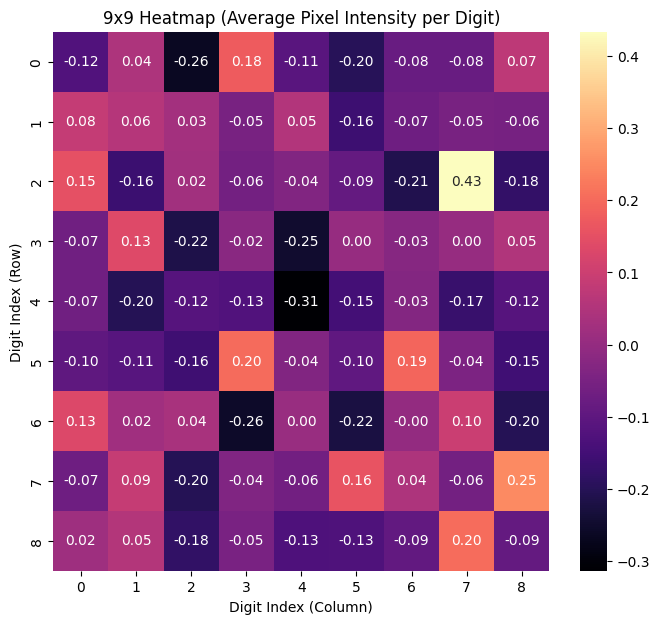

In [ ]:
import seaborn as sns

def plot_mnist_9x9_heatmap(dataset):
    n = 9
    intensities = []
    

    for i in range(n * n):
        img, _ = dataset[i]
        avg_intensity = img.mean().item()
        intensities.append(avg_intensity)
    
    heatmap_data = np.array(intensities).reshape(n, n)
    
    plt.figure(figsize=(8, 7))
    sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='magma')
    plt.title("9x9 Heatmap (Average Pixel Intensity per Digit)")
    plt.xlabel("Digit Index (Column)")
    plt.ylabel("Digit Index (Row)")
    plt.show()

plot_mnist_9x9_heatmap(mnist_test)


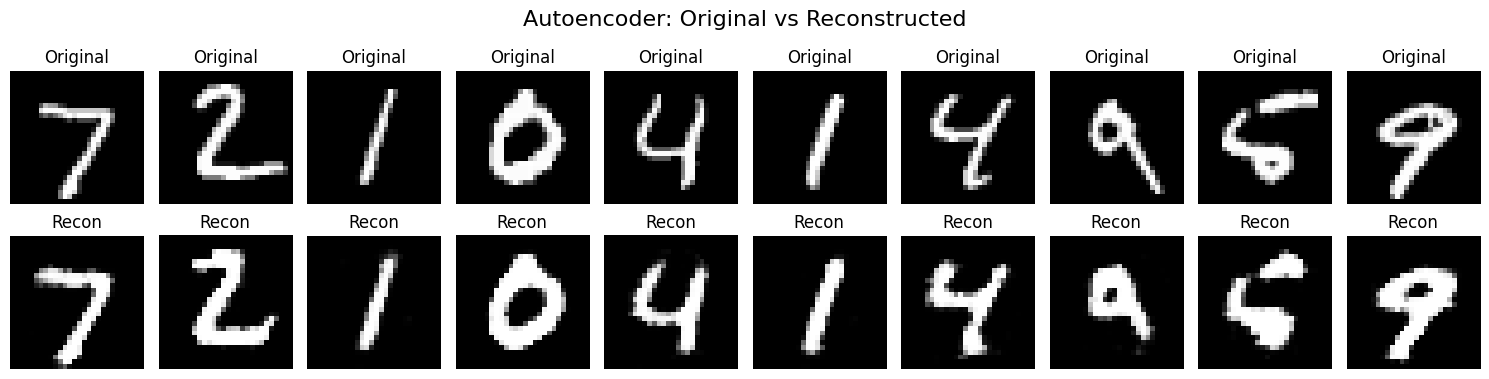

In [ ]:
def visualize_ae_reconstruction(model, dataset, num_samples=10):
    model.eval()
    fig, axes = plt.subplots(2, num_samples, figsize=(15, 4))
    
    for i in range(num_samples):
        img, _ = dataset[i]
        
        with torch.no_grad():
            reconstructed = model(img.unsqueeze(0))
        

        axes[0, i].imshow(img.squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')
        

        axes[1, i].imshow(reconstructed.squeeze().cpu(), cmap='gray')
        axes[1, i].set_title("Recon")
        axes[1, i].axis('off')
    
    plt.suptitle("Autoencoder: Original vs Reconstructed", fontsize=16)
    plt.tight_layout()
    plt.show()

visualize_ae_reconstruction(model_ae, mnist_test)


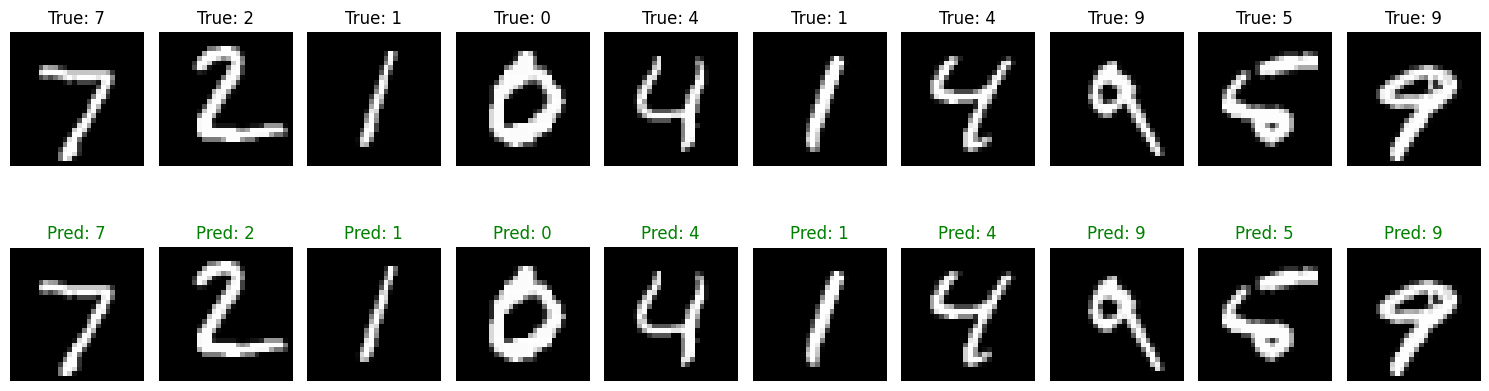

In [119]:
def visualize_predictions_grid(model, dataset, num_samples=10):
    model.eval()
    fig, axes = plt.subplots(2, num_samples, figsize=(15, 5))
    
    for i in range(num_samples):
        # Берем изображение из теста
        img, label = dataset[i]
        
        # Получаем предсказание
        with torch.no_grad():
            output = model(img.unsqueeze(0))
            pred = output.argmax(dim=1).item()
        
        # ВЕРХНИЙ РЯД: Реальное изображение и его метка
        axes[0, i].imshow(img.squeeze(), cmap='gray')
        axes[0, i].set_title(f"True: {label}")
        axes[0, i].axis('off')
        
        # НИЖНИЙ РЯД: То же изображение, но заголовок с предсказанием
        axes[1, i].imshow(img.squeeze(), cmap='gray')
        color = 'green' if pred == label else 'red'
        axes[1, i].set_title(f"Pred: {pred}", color=color)
        axes[1, i].axis('off')
    
    plt.tight_layout()
    plt.show()

# Запуск для первых 10 цифр
visualize_predictions_grid(model_cls, mnist_test)
